# Visualización programática con Python
## Seaborn · Plotly · Streamlit

En esta sesión trabajaremos con tres librerías habituales en análisis de datos:

- **Seaborn** para visualización estadística.
- **Plotly** para gráficos interactivos.
- **Streamlit** para construir pequeñas aplicaciones de datos.

Los ejemplos utilizan tres conjuntos de datos sencillos:

1. Hábitos de estudiantes y resultados académicos.
2. Movilidad urbana mensual.
3. Calidad del aire y variables meteorológicas.

## Preparación

Los datos se cargan desde ficheros CSV, del mismo modo que ocurriría en un proyecto real.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

estudiantes = pd.read_csv("estudiantes_habitos.csv")
movilidad = pd.read_csv("movilidad_urbana.csv", parse_dates=["fecha"])
aire = pd.read_csv("calidad_aire.csv", parse_dates=["fecha"])

estudiantes.head()

,horas_sueno,horas_estudio_dia,actividad_fisica_min,uso_pantallas_horas,asistencia_pct,nota_final,grupo
0,7.6,7.6,73,5.0,87.0,8.39,Grupo A
1,7.0,6.5,56,4.3,80.5,7.32,Grupo A
2,7.7,3.5,57,3.6,92.3,7.32,Grupo A
3,8.6,5.3,62,4.9,94.5,7.21,Grupo A
4,6.9,4.5,60,3.3,74.1,6.77,Grupo C


# 1. Seaborn

## Distribución de una variable

Comenzamos estudiando la distribución de la nota final.

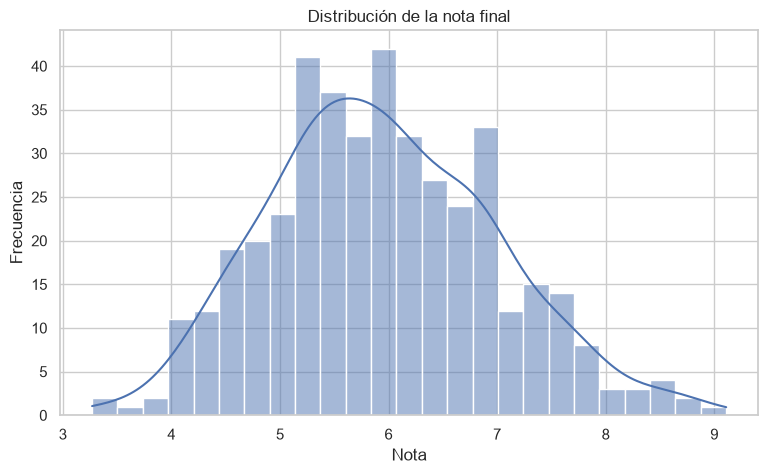

In [2]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=estudiantes,
    x="nota_final",
    bins=25,
    kde=True
)

plt.title("Distribución de la nota final")
plt.xlabel("Nota")
plt.ylabel("Frecuencia")

plt.show()

La curva suavizada permite ver la forma general de la distribución, mientras que el histograma mantiene visible la frecuencia observada en cada intervalo.

## Relación entre dos variables

Podemos estudiar la relación entre las horas de estudio y la nota final.

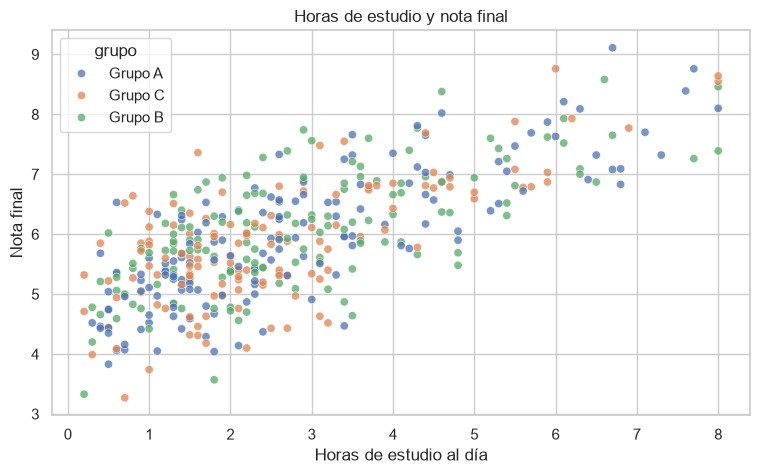

In [3]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=estudiantes,
    x="horas_estudio_dia",
    y="nota_final",
    hue="grupo",
    alpha=0.75
)

plt.title("Horas de estudio y nota final")
plt.xlabel("Horas de estudio al día")
plt.ylabel("Nota final")

plt.show()

## Matriz de correlaciones

Una matriz de correlaciones resume la intensidad y el signo de la relación lineal entre variables numéricas.

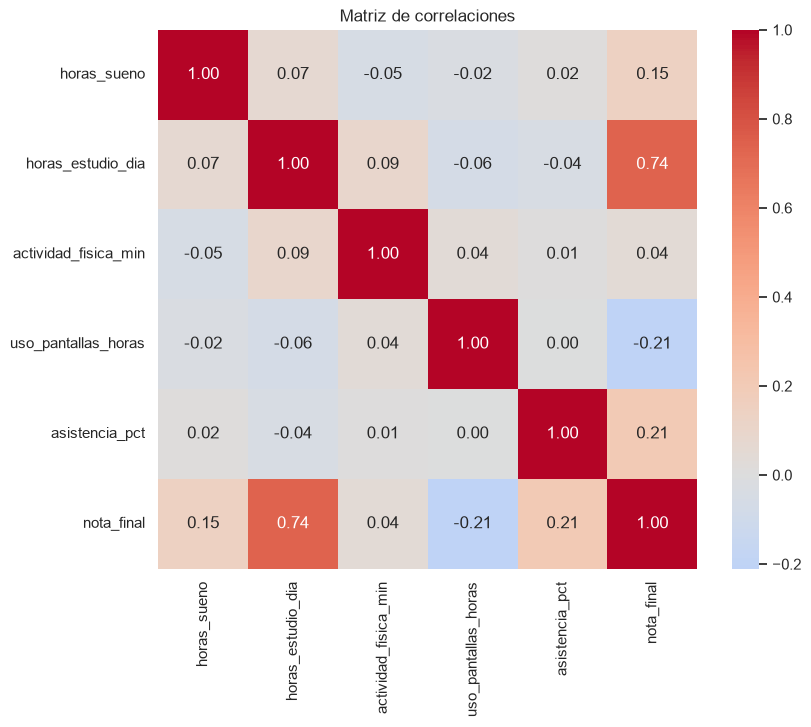

In [4]:
variables = [
    "horas_sueno",
    "horas_estudio_dia",
    "actividad_fisica_min",
    "uso_pantallas_horas",
    "asistencia_pct",
    "nota_final"
]

corr = estudiantes[variables].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Matriz de correlaciones")

plt.show()

# 2. Plotly

## Scatter interactivo

La misma idea de dispersión puede representarse de forma interactiva. En este caso añadimos más información mediante color, tamaño y `hover`.

In [5]:
fig = px.scatter(
    estudiantes,
    x="horas_estudio_dia",
    y="nota_final",
    color="grupo",
    size="asistencia_pct",
    hover_data=[
        "horas_sueno",
        "uso_pantallas_horas",
        "actividad_fisica_min"
    ],
    title="Hábitos de estudio y rendimiento",
    labels={
        "horas_estudio_dia": "Horas de estudio al día",
        "nota_final": "Nota final",
        "grupo": "Grupo",
        "asistencia_pct": "Asistencia (%)"
    }
)

fig.show()

## Serie temporal interactiva

El segundo ejemplo utiliza datos mensuales de movilidad urbana.

In [6]:
fig = px.line(
    movilidad,
    x="fecha",
    y="viajes_miles",
    color="zona",
    markers=True,
    title="Evolución mensual de la movilidad urbana",
    labels={
        "fecha": "Fecha",
        "viajes_miles": "Viajes (miles)",
        "zona": "Zona"
    }
)

fig.show()

Plotly permite hacer zoom, consultar valores exactos y activar o desactivar series desde la leyenda.

# 3. Streamlit

Streamlit permite convertir un script de Python en una aplicación web sencilla. Los widgets funcionan como entradas del usuario y actualizan el contenido de la aplicación.

## Aplicación 1: explorador de una distribución normal

Esta aplicación permite modificar los parámetros de una distribución normal y observar cómo cambia la muestra generada.

In [8]:
%%writefile streamlit_normal.py

import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(
    page_title="Distribución normal",
    layout="wide"
)

st.title("Explorador de una distribución normal")

st.sidebar.header("Parámetros")

mu = st.sidebar.slider(
    "Media",
    min_value=-5.0,
    max_value=5.0,
    value=0.0,
    step=0.1
)

sigma = st.sidebar.slider(
    "Desviación estándar",
    min_value=0.2,
    max_value=4.0,
    value=1.0,
    step=0.1
)

n = st.sidebar.slider(
    "Número de observaciones",
    min_value=100,
    max_value=5000,
    value=1000,
    step=100
)

np.random.seed(42)

datos = np.random.normal(mu, sigma, n)

df = pd.DataFrame({
    "valor": datos
})

c1, c2, c3 = st.columns(3)

c1.metric("Media observada", f"{datos.mean():.2f}")
c2.metric("Desviación estándar", f"{datos.std():.2f}")
c3.metric("Observaciones", f"{len(datos):,}")

fig = px.histogram(
    df,
    x="valor",
    nbins=40,
    marginal="box",
    histnorm="probability density",
    title="Distribución generada"
)

st.plotly_chart(fig, use_container_width=True)

st.subheader("Resumen estadístico")
st.dataframe(df.describe(), use_container_width=True)

Writing streamlit_normal.py


Para ejecutar la aplicación:

```bash
python -m streamlit run streamlit_normal.py
```

Se puede modificar en directo la media, la desviación estándar y el tamaño de la muestra.

## Aplicación 2: explorador de calidad del aire

La segunda aplicación utiliza un CSV y combina filtros, métricas, gráficos y tabla.

In [9]:
%%writefile streamlit_aire.py

import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(
    page_title="Calidad del aire",
    layout="wide"
)

st.title("Explorador de calidad del aire")

df = pd.read_csv(
    "calidad_aire.csv",
    parse_dates=["fecha"]
)

st.sidebar.header("Filtros")

pm_max = st.sidebar.slider(
    "PM2.5 máximo",
    min_value=float(df["pm25"].min()),
    max_value=float(df["pm25"].max()),
    value=float(df["pm25"].max())
)

temp_min, temp_max = st.sidebar.slider(
    "Rango de temperatura",
    min_value=float(df["temperatura_c"].min()),
    max_value=float(df["temperatura_c"].max()),
    value=(
        float(df["temperatura_c"].min()),
        float(df["temperatura_c"].max())
    )
)

vista = df[
    (df["pm25"] <= pm_max)
    & df["temperatura_c"].between(temp_min, temp_max)
]

c1, c2, c3 = st.columns(3)

c1.metric("Días", len(vista))
c2.metric("PM2.5 medio", f"{vista['pm25'].mean():.1f}")
c3.metric("Temperatura media", f"{vista['temperatura_c'].mean():.1f} ºC")

fig1 = px.scatter(
    vista,
    x="indice_trafico",
    y="pm25",
    color="temperatura_c",
    size="viento_ms",
    hover_data=["fecha", "humedad_pct"],
    title="Tráfico y concentración de PM2.5"
)

st.plotly_chart(fig1, use_container_width=True)

fig2 = px.line(
    vista.sort_values("fecha"),
    x="fecha",
    y="pm25",
    title="Evolución temporal de PM2.5"
)

st.plotly_chart(fig2, use_container_width=True)

st.subheader("Datos filtrados")
st.dataframe(vista, use_container_width=True)

Writing streamlit_aire.py


Para ejecutar la segunda aplicación:

```bash
python -m streamlit run streamlit_aire.py
```

Los filtros permiten modificar en directo el rango de temperatura y el nivel máximo de PM2.5.

# Resumen

| Herramienta | Tipo de visualización |
|---|---|
| Seaborn | Estadística y exploratoria |
| Plotly | Interactiva |
| Streamlit | Aplicaciones y dashboards |

Una secuencia habitual de trabajo es:

**cargar datos → explorar → visualizar → construir una aplicación**